# Bài 6: Giảm số màu trong ảnh bằng thuật toán k-Means

Sử dụng thuật toán k-Means để giảm số màu trong ảnh, từ đó giảm kích thước file ảnh theo ý muốn.

> Lưu ý: đặt file ảnh `dog.png` cùng thư mục với notebook (hoặc đổi đường dẫn ở bước 2). Trên Google Colab, hãy tải file ảnh lên trước khi chạy.

## 1. Khai báo các thư viện vào bài làm

In [15]:
print("Họ và tên: Lê Quốc Trung - MSSV: 6451071082")
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
from PIL import Image
import numpy as np
import os
%matplotlib inline

Họ và tên: Lê Quốc Trung - MSSV: 6451071082


## 2. Đọc vào file ảnh cần giảm kích thước và hiển thị ra màn hình

Họ và tên: Lê Quốc Trung - MSSV: 6451071082


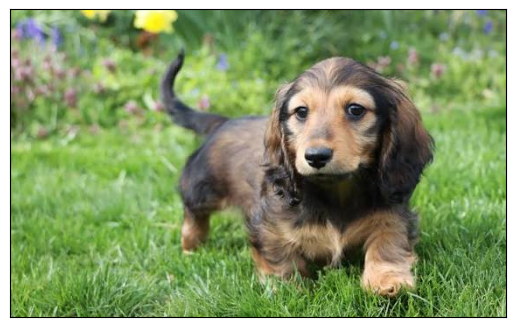

In [16]:
print("Họ và tên: Lê Quốc Trung - MSSV: 6451071082")
image = Image.open('/dog.png').convert('RGB')   # convert('RGB') để bỏ kênh alpha (nếu có)
axes = plt.axes(xticks=[], yticks=[])
axes.imshow(image)

## 3. Chuyển ảnh đọc được thành mảng số và lấy thông tin chiều rộng, cao của ảnh

In [17]:
print("Họ và tên: Lê Quốc Trung - MSSV: 6451071082")
imarr = np.array(image)
rows = imarr.shape[0]
cols = imarr.shape[1]
print("Kích thước ảnh: cao =", rows, ", rộng =", cols, ", sâu =", imarr.shape[2])

Họ và tên: Lê Quốc Trung - MSSV: 6451071082
Kích thước ảnh: cao = 352 , rộng = 567 , sâu = 3


## 4. Biến đổi giá trị màu từ đoạn [0...255] về đoạn [0...1] và chuyển dạng mảng từ 3 chiều (cao, rộng, sâu) thành 2 chiều (cao x rộng, sâu)

In [18]:
print("Họ và tên: Lê Quốc Trung - MSSV: 6451071082")
data = imarr / 255.0   # đưa về thang 0...1
data = data.reshape(rows * cols, 3)
print(data.shape)

Họ và tên: Lê Quốc Trung - MSSV: 6451071082
(199584, 3)


## 5. Chạy thuật toán gom cụm với số màu mong muốn là 32, sau đó lấy ra mảng biểu diễn hình sau khi đã gom cụm

In [19]:
print("Họ và tên: Lê Quốc Trung - MSSV: 6451071082")
kmeans = KMeans(n_clusters=32, max_iter=300)
kmeans.fit(data)
new_colors = kmeans.cluster_centers_[kmeans.predict(data)]
print("Số màu sau khi gom cụm:", len(kmeans.cluster_centers_))

Họ và tên: Lê Quốc Trung - MSSV: 6451071082
Số màu sau khi gom cụm: 32


## 6. Khôi phục dạng mảng vừa thu được từ 2 chiều thành 3 chiều như ban đầu

In [20]:
print("Họ và tên: Lê Quốc Trung - MSSV: 6451071082")
img_recolored = new_colors.reshape(imarr.shape)
print(img_recolored.shape)

Họ và tên: Lê Quốc Trung - MSSV: 6451071082
(352, 567, 3)


## 7. Biểu diễn hình kết quả và so sánh với ảnh gốc ban đầu

Họ và tên: Lê Quốc Trung - MSSV: 6451071082


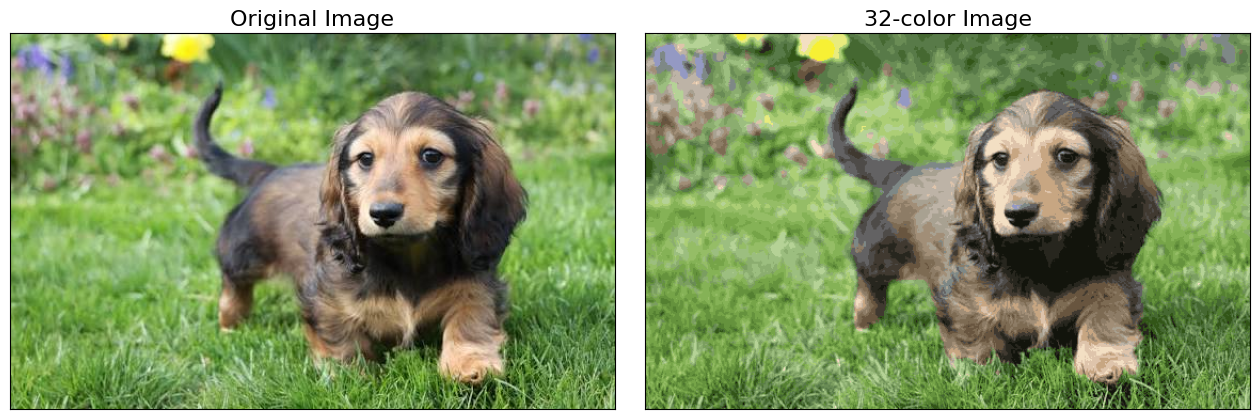

In [21]:
print("Họ và tên: Lê Quốc Trung - MSSV: 6451071082")
fig, ax = plt.subplots(1, 2, figsize=(16, 6),
                       subplot_kw=dict(xticks=[], yticks=[]))
fig.subplots_adjust(wspace=0.05)
ax[0].imshow(image)
ax[0].set_title('Original Image', size=16)
ax[1].imshow(img_recolored)
ax[1].set_title('32-color Image', size=16);

## 8. Lưu hình kết quả xuống đĩa cứng

In [22]:
print("Họ và tên: Lê Quốc Trung - MSSV: 6451071082")
img_recolored = img_recolored * 255
new_img = Image.fromarray(img_recolored.astype(np.uint8))
new_img.save('compressed_img2.png')

# So sánh dung lượng file trước và sau khi giảm số màu
size_goc = os.path.getsize('/dog.png') / 1024
size_moi = os.path.getsize('compressed_img2.png') / 1024
print(f"Dung lượng ảnh gốc    : {size_goc:.1f} KB")
print(f"Dung lượng ảnh đã nén : {size_moi:.1f} KB")
print(f"Tỉ lệ giảm            : {(1 - size_moi / size_goc) * 100:.1f}%")



Họ và tên: Lê Quốc Trung - MSSV: 6451071082
Dung lượng ảnh gốc    : 370.6 KB
Dung lượng ảnh đã nén : 121.5 KB
Tỉ lệ giảm            : 67.2%
